In [49]:
import tensorflow as tf

gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print("GPU configuration error:", e)

# IMPORTING LIBRARIES

In [50]:
import numpy as np
import pandas as pd
import tensorflow as tf
import cv2
import os
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tqdm import tqdm
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [51]:
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
tf.config.experimental.set_memory_growth(tf.config.experimental.list_physical_devices('GPU')[0], True)

Num GPUs Available: 2


# LOADING DATA

In [52]:
img_size = 224
batch_size = 32
csv_path = "/kaggle/input/aptos-2019-blindness-detection/APTOS 2019 Blindness Detection/train.csv"
img_dir = "/kaggle/input/aptos-2019-blindness-detection/APTOS 2019 Blindness Detection/train_images"
save_dir = "/kaggle/working/preprocessed_images" 

In [53]:
os.makedirs(save_dir, exist_ok=True)

In [54]:
df = pd.read_csv(csv_path)
df["id_code"] = df["id_code"].apply(lambda x: os.path.join(img_dir, x + ".png"))

# CLACHE PREPROCESSING

In [55]:
def apply_clahe_and_save(image_path, save_dir):
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Unable to read image at path: {image_path}")
    image = cv2.resize(image, (img_size, img_size))
    
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    
    
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    
    
    merged_lab = cv2.merge((cl, a, b))
    final_image = cv2.cvtColor(merged_lab, cv2.COLOR_LAB2RGB)
    
    
    save_path = os.path.join(save_dir, os.path.basename(image_path))
    cv2.imwrite(save_path, cv2.cvtColor(final_image, cv2.COLOR_RGB2BGR))
    
    return final_image / 255.0

In [56]:
print("Preprocessing images and saving to disk...")
for image_path in tqdm(df["id_code"], desc="Processing Images"):  
    apply_clahe_and_save(image_path, save_dir)
print("Preprocessing complete!")

Preprocessing images and saving to disk...


Processing Images: 100%|██████████| 3662/3662 [06:16<00:00,  9.73it/s]

Preprocessing complete!


# LOADING PREPROCESSED DATA INTO TF DATASET

In [57]:
def load_preprocessed_image(image_path, label):
    image = tf.io.read_file(image_path)
    
    image = tf.image.decode_png(image, channels=3)
    image = tf.image.resize(image, [img_size, img_size])
    image = tf.cast(image, tf.float32) / 255.0
    
    return image, label

In [58]:
image_paths = [os.path.join(save_dir, os.path.basename(path)) for path in df["id_code"]]
labels = df["diagnosis"].values
dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))
dataset = dataset.shuffle(len(df)).map(load_preprocessed_image, num_parallel_calls=tf.data.AUTOTUNE)
dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

# BEFORE AND AFTER CLACHE PREPROCESS

In [59]:
def visualize_clahe_effect(df_sample):
    fig, axes = plt.subplots(len(df_sample), 2, figsize=(10, 5 * len(df_sample)))
    
    for i, row in enumerate(df_sample.itertuples()):
        img_path = row.id_code
        original = cv2.imread(img_path, cv2.IMREAD_COLOR)
        original = cv2.resize(original, (img_size, img_size))
        original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
        
        processed_path = os.path.join(save_dir, os.path.basename(img_path))
        processed = cv2.imread(processed_path, cv2.IMREAD_COLOR)
        processed = cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)
        
        axes[i, 0].imshow(original)
        axes[i, 0].set_title(f"Original - {row.diagnosis}")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(processed)
        axes[i, 1].set_title(f"CLAHE Processed - {row.diagnosis}")
        axes[i, 1].axis("off")
    
    plt.show()

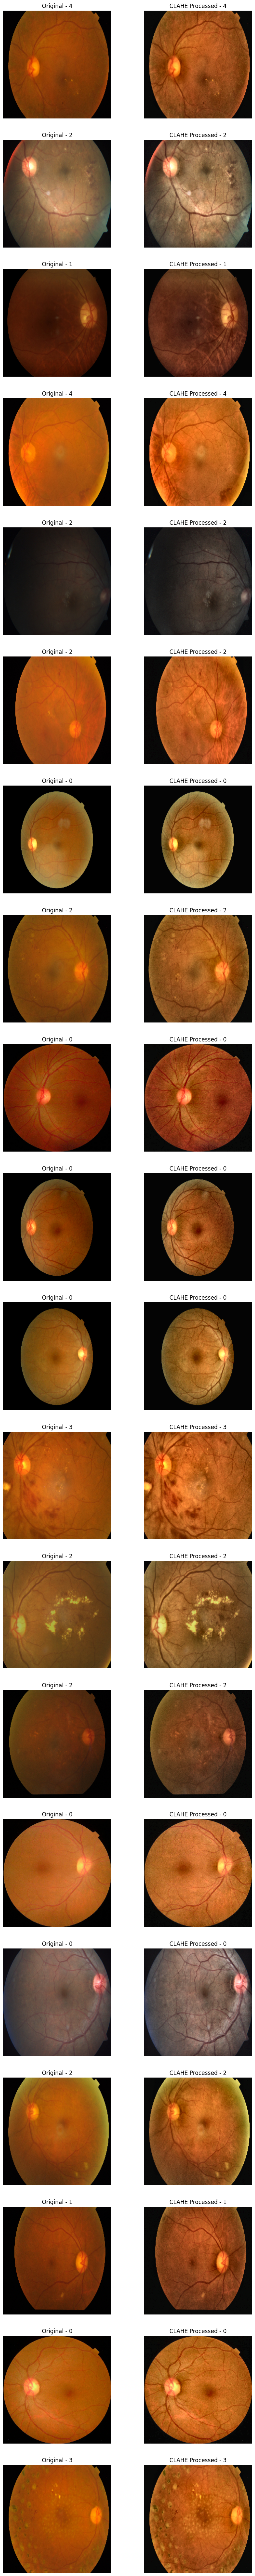

In [60]:
df_sample = df.sample(20)
visualize_clahe_effect(df_sample)

# SPLITTING AND PREFETCHING DATASET

In [61]:
def dataset_split(ds, train=0.7, val=0.15, test=0.15):
    ds_size = len(ds)
    train_size = int(ds_size * train)
    val_size = int(ds_size * val)
    
    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size + val_size)
    
    return train_ds, val_ds, test_ds

In [62]:
train_ds, val_ds, test_ds = dataset_split(dataset)
train_ds = train_ds.cache().shuffle(1000).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.cache().prefetch(tf.data.AUTOTUNE)

# MULTIBRANCH CNN WITH TRANSFER LEARNING

In [63]:
from tensorflow.keras.applications import DenseNet201,ResNet50
from sklearn.utils.class_weight import compute_class_weight

In [64]:
base1 = DenseNet201(weights="imagenet", include_top=False, input_shape=(img_size, img_size, 3))
base2 = ResNet50(weights="imagenet", include_top=False, input_shape=(img_size, img_size, 3))

In [65]:
base1.trainable = True
base2.trainable = True

In [66]:
for layer in base1.layers[:-10]:  
    layer.trainable = False
for layer in base2.layers[:-10]:  
    layer.trainable = False

In [67]:
inputs = tf.keras.Input(shape=(img_size, img_size, 3))
x1 = layers.GlobalAveragePooling2D()(base1(inputs))
x2 = layers.GlobalAveragePooling2D()(base2(inputs))
merged = layers.Concatenate()([x1, x2])
x = layers.Dense(256, activation="relu")(merged)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(5, activation="softmax")(x)

In [68]:
multibranch_model_1 = Model(inputs, outputs)
multibranch_model_1.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ densenet201         │ (None, 7, 7,      │ 18,321,984 │ input_layer_6[0]… │
│ (Functional)        │ 1920)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ input_layer_6[0]… │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1920)      │          0 │ densenet201[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 3968)      │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 256)       │  1,016,064 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 256)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 5)         │      1,285 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 42,927,045 (163.75 MB)

 Trainable params: 5,769,413 (22.01 MB)

 Non-trainable params: 37,157,632 (141.75 MB)

In [69]:
multibranch_model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

In [70]:
class_weights = compute_class_weight("balanced", classes=np.unique(labels), y=labels)
class_weights = dict(enumerate(class_weights))

In [71]:
def lr_scheduler(epoch, lr):
    if epoch > 0 and epoch % 10 == 0:  
        return lr * 0.1
    return lr

lr_callback = tf.keras.callbacks.LearningRateScheduler(lr_scheduler)

In [72]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,  
    restore_best_weights=True
)

In [73]:
multibranch_history = multibranch_model_1.fit(
    train_ds,
    epochs=50,
    batch_size=batch_size,
    verbose=1,
    class_weight=class_weights,
    validation_data=val_ds,
    callbacks=[lr_callback,early_stopping]
)

Epoch 1/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 120s 598ms/step - accuracy: 0.4173 - loss: 1.6036 - val_accuracy: 0.5809 - val_loss: 1.0303 - learning_rate: 1.0000e-04
Epoch 2/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 23s 282ms/step - accuracy: 0.6024 - loss: 1.1713 - val_accuracy: 0.5643 - val_loss: 1.0704 - learning_rate: 1.0000e-04
Epoch 3/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 22s 280ms/step - accuracy: 0.6574 - loss: 1.0435 - val_accuracy: 0.5662 - val_loss: 1.1082 - learning_rate: 1.0000e-04
Epoch 4/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 268ms/step - accuracy: 0.6953 - loss: 0.9299 - val_accuracy: 0.7077 - val_loss: 0.8083 - learning_rate: 1.0000e-04
Epoch 5/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 22s 274ms/step - accuracy: 0.7469 - loss: 0.8621 - val_accuracy: 0.8364 - val_loss: 0.6063 - learning_rate: 1.0000e-04
Epoch 6/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 23s 287ms/step - accuracy: 0.7784 - loss: 0.7696 - val_accuracy: 0.8088 - val_loss: 0.5346 - learning_rate: 1.0000e-04
Epoch 7/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 22s 274ms/step - ac

In [74]:
multibranch_model_1.save("multibranch_model_1.keras")
multibranch_model_1.save("multibranch_model_1.h5")

In [75]:
test_loss, test_acc = multibranch_model_1.evaluate(test_ds)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

18/18 ━━━━━━━━━━━━━━━━━━━━ 17s 908ms/step - accuracy: 0.9281 - loss: 0.2601
Test Accuracy: 93.01%


# 2D CNN

In [76]:
def build_2d_cnn(input_shape=(224, 224, 3), num_classes=5):
    inputs = tf.keras.Input(shape=input_shape)
    
    
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(128, (3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    
    
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    
    
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    
    
    cnn_model = Model(inputs, outputs)
    return cnn_model

In [77]:
cnn_model = build_2d_cnn(input_shape=(img_size, img_size, 3), num_classes=5)
cnn_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,784,901 (98.36 MB)

 Trainable params: 25,784,901 (98.36 MB)

 Non-trainable params: 0 (0.00 B)

In [78]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

In [79]:
cnn_history = cnn_model.fit(
    train_ds,
    epochs=40,
    batch_size=batch_size,
    verbose=1,
    class_weight=class_weights,
    validation_data=val_ds,
    callbacks=[lr_callback]
)

Epoch 1/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step - accuracy: 0.3860 - loss: 1.5830 - val_accuracy: 0.5276 - val_loss: 1.0638 - learning_rate: 1.0000e-04
Epoch 2/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.6001 - loss: 1.2672 - val_accuracy: 0.6912 - val_loss: 0.8480 - learning_rate: 1.0000e-04
Epoch 3/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.6512 - loss: 1.2093 - val_accuracy: 0.6581 - val_loss: 0.8844 - learning_rate: 1.0000e-04
Epoch 4/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.6273 - loss: 1.1513 - val_accuracy: 0.7059 - val_loss: 0.8258 - learning_rate: 1.0000e-04
Epoch 5/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.6875 - loss: 1.0716 - val_accuracy: 0.6820 - val_loss: 0.8741 - learning_rate: 1.0000e-04
Epoch 6/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 55ms/step - accuracy: 0.6555 - loss: 1.1256 - val_accuracy: 0.7206 - val_loss: 0.7484 - learning_rate: 1.0000e-04
Epoch 7/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.6916 

In [80]:
cnn_model.save("cnn_model_1.keras")
cnn_model.save("cnn_model_1.h5")

In [81]:
test_loss, test_acc = cnn_model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.7837 - loss: 0.6193
Test Accuracy: 77.42%


# VISUALIZATION OF MODEL TRAININGS

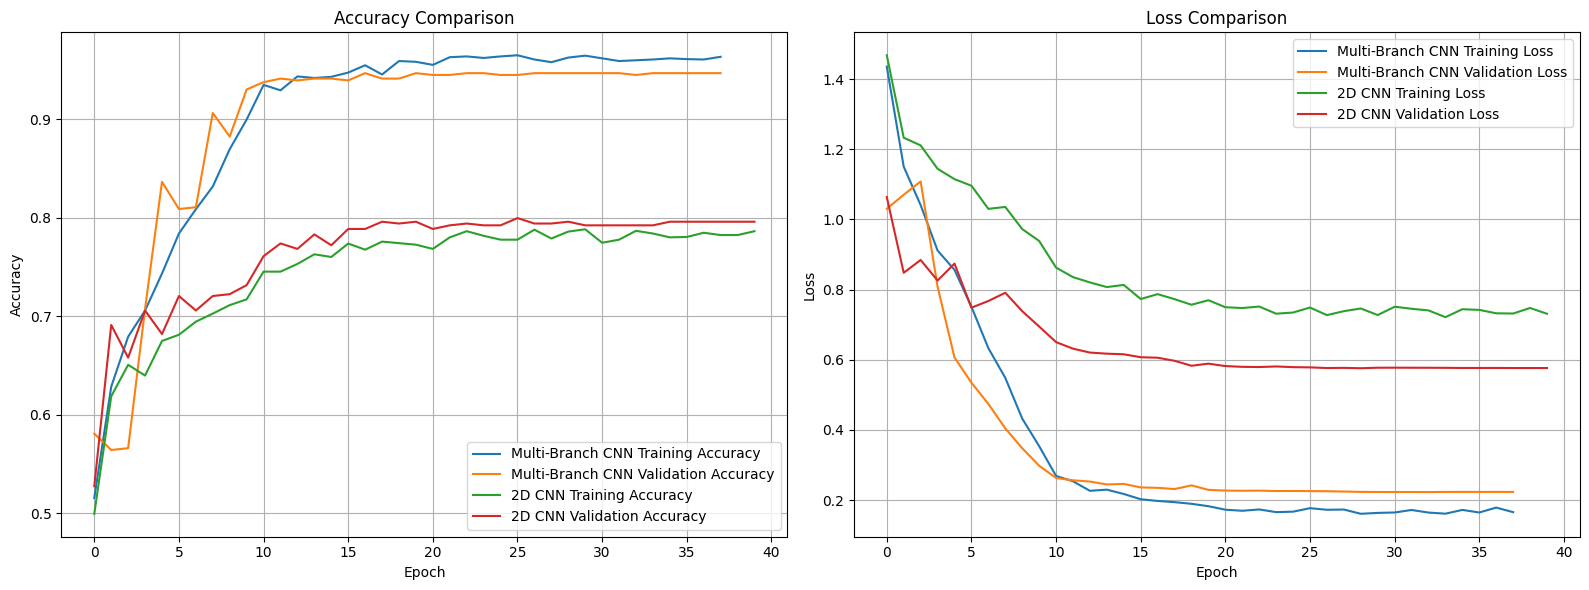

In [82]:
import matplotlib.pyplot as plt


if hasattr(multibranch_history, 'history'):
    multibranch_history = multibranch_history.history

if hasattr(cnn_history, 'history'):
    cnn_history = cnn_history.history


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(multibranch_history['accuracy'], label='Multi-Branch CNN Training Accuracy')
axes[0].plot(multibranch_history['val_accuracy'], label='Multi-Branch CNN Validation Accuracy')
axes[0].plot(cnn_history['accuracy'], label='2D CNN Training Accuracy')
axes[0].plot(cnn_history['val_accuracy'], label='2D CNN Validation Accuracy')
axes[0].set_title('Accuracy Comparison')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)


axes[1].plot(multibranch_history['loss'], label='Multi-Branch CNN Training Loss')
axes[1].plot(multibranch_history['val_loss'], label='Multi-Branch CNN Validation Loss')
axes[1].plot(cnn_history['loss'], label='2D CNN Training Loss')
axes[1].plot(cnn_history['val_loss'], label='2D CNN Validation Loss')
axes[1].set_title('Loss Comparison')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [83]:
multibranch_predictions = multibranch_model_1.predict(test_ds)
cnn_predictions = cnn_model.predict(test_ds)

18/18 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step 
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step


In [84]:
multibranch_class_labels = np.argmax(multibranch_predictions, axis=1) 
cnn_class_labels = np.argmax(cnn_predictions, axis=1)

true_labels = np.concatenate([y for x, y in test_ds], axis=0)

In [85]:
multibranch_cm = confusion_matrix(true_labels, multibranch_class_labels)
cnn_cm = confusion_matrix(true_labels, cnn_class_labels)

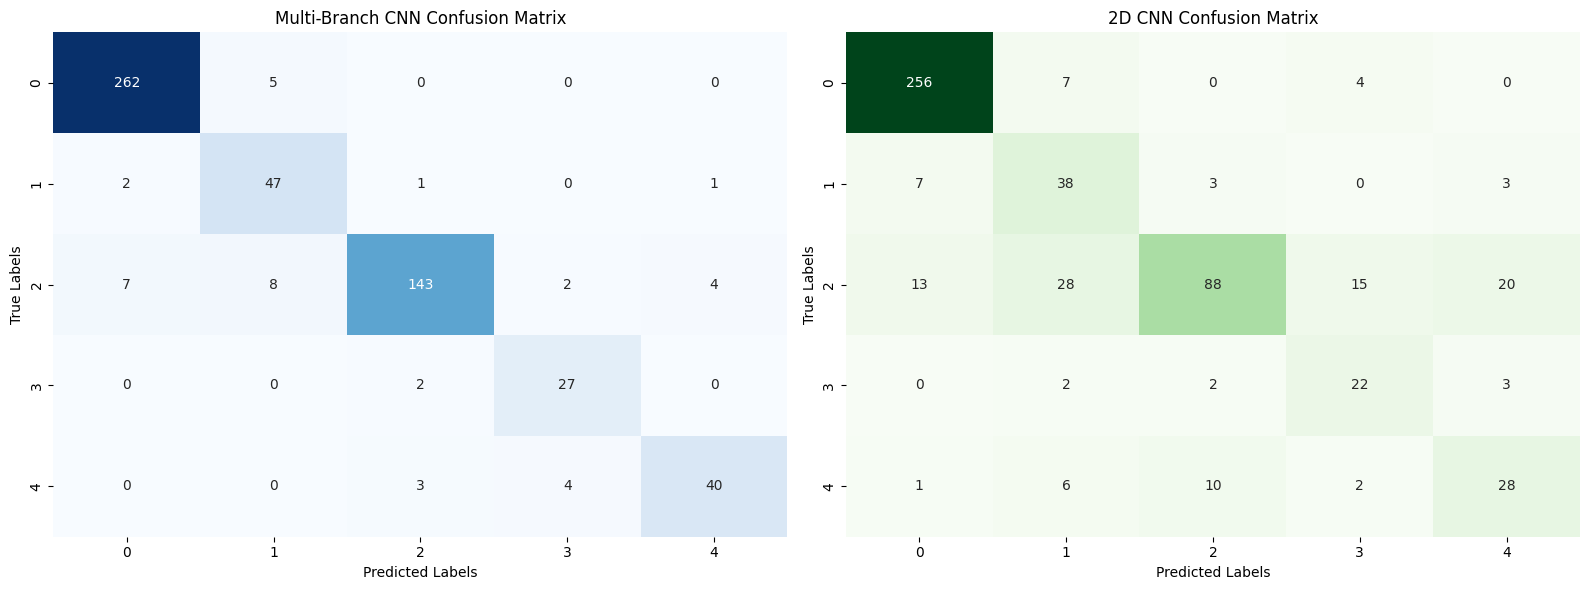

In [86]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
sns.heatmap(multibranch_cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Multi-Branch CNN Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')

plt.subplot(1, 2, 2)
sns.heatmap(cnn_cm, annot=True, fmt='d', cmap='Greens', cbar=False)
plt.title('2D CNN Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')

plt.tight_layout()
plt.show()

# ENSEMBLE MODEL

In [87]:
multibranch_model=tf.keras.models.load_model("/kaggle/working/multibranch_model_1.h5")
cnn_model = tf.keras.models.load_model("/kaggle/working/cnn_model_1.h5")

In [88]:
weight_multibranch = 0.7
weight_cnn = 0.3

In [89]:
ensemble_predictions = (weight_multibranch * multibranch_predictions) + (weight_cnn * cnn_predictions)
ensemble_class_labels = np.argmax(ensemble_predictions, axis=1)
true_labels = np.concatenate([y for x, y in test_ds], axis=0)
ensemble_accuracy = np.mean(ensemble_class_labels == true_labels)
print(f"Ensemble Accuracy: {ensemble_accuracy * 100:.2f}%")

Ensemble Accuracy: 92.29%


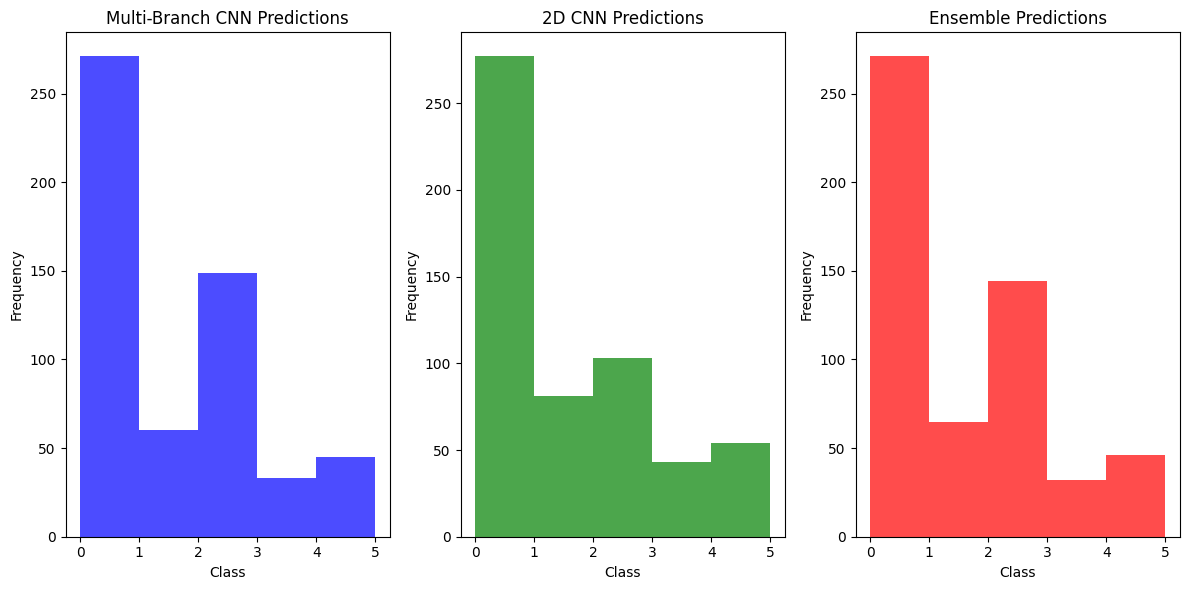

In [90]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.hist(multibranch_class_labels, bins=5, range=(0, 5), alpha=0.7, color='blue')
plt.title('Multi-Branch CNN Predictions')
plt.xlabel('Class')
plt.ylabel('Frequency')

plt.subplot(1, 3, 2)
plt.hist(cnn_class_labels, bins=5, range=(0, 5), alpha=0.7, color='green')
plt.title('2D CNN Predictions')
plt.xlabel('Class')
plt.ylabel('Frequency')


plt.subplot(1, 3, 3)
plt.hist(ensemble_class_labels, bins=5, range=(0, 5), alpha=0.7, color='red')
plt.title('Ensemble Predictions')
plt.xlabel('Class')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# PREDICTING WITH USER INPUTS

In [91]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

In [92]:
def preprocess_image(image_path, img_size=224):
    
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Unable to read image at path: {image_path}")

    image = cv2.resize(image, (img_size, img_size))
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_clahe = clahe.apply(l)

    merged_lab = cv2.merge((l_clahe, a, b))
    final_image = cv2.cvtColor(merged_lab, cv2.COLOR_LAB2RGB)

    final_image = final_image / 255.0  
    return final_image

In [93]:
def saliency_map(model, img_array):
   
    img_tensor = tf.convert_to_tensor(img_array)
    with tf.GradientTape() as tape:
        tape.watch(img_tensor)
        predictions = model(img_tensor)
        top_pred = tf.argmax(predictions[0])
        loss = predictions[:, top_pred]

    grads = tape.gradient(loss, img_tensor)[0]
    saliency = tf.reduce_max(tf.abs(grads), axis=-1).numpy()
    return saliency

In [94]:
def predict_with_explanations(image_path, multibranch_model, cnn_model, img_size=224, weight_multibranch=0.7, weight_cnn=0.3):
    
    
    preprocessed_image = preprocess_image(image_path, img_size)
    img_array = np.expand_dims(preprocessed_image, axis=0)  

    
    multibranch_probs = multibranch_model.predict(img_array, verbose=0)[0]
    multibranch_class = np.argmax(multibranch_probs)
    multibranch_confidence = float(multibranch_probs[multibranch_class])

    
    cnn_probs = cnn_model.predict(img_array, verbose=0)[0]
    cnn_class = np.argmax(cnn_probs)
    cnn_confidence = float(cnn_probs[cnn_class])

    
    ensemble_probs = (weight_multibranch * multibranch_probs) + (weight_cnn * cnn_probs)
    ensemble_class = np.argmax(ensemble_probs)
    ensemble_confidence = float(ensemble_probs[ensemble_class])

    
    multibranch_saliency = saliency_map(multibranch_model, img_array)

    
    cnn_saliency = saliency_map(cnn_model, img_array)

    
    results = {
        "multi_branch_cnn": {
            "class": int(multibranch_class),
            "confidence": multibranch_confidence,
            "probabilities": [float(prob) for prob in multibranch_probs],
            "saliency_map": multibranch_saliency,
        },
        "2d_cnn": {
            "class": int(cnn_class),
            "confidence": cnn_confidence,
            "probabilities": [float(prob) for prob in cnn_probs],
            "saliency_map": cnn_saliency,
        },
        "ensemble": {
            "class": int(ensemble_class),
            "confidence": ensemble_confidence,
            "probabilities": [float(prob) for prob in ensemble_probs],
        },
    }
    return results

In [95]:
def visualize_results(results, original_image):
    """
    Visualizes the predictions and Saliency Map explanations.

    Args:
        results (dict): Dictionary containing predictions and Saliency Maps.
        original_image (np.array): Original input image.
    """
    plt.figure(figsize=(18, 12))

    
    plt.subplot(2, 2, 1)
    plt.imshow(original_image)
    plt.title("Original Image")
    plt.axis("off")

    
    plt.subplot(2, 2, 2)
    plt.imshow(results["multi_branch_cnn"]["saliency_map"], cmap="hot")
    plt.title("Saliency Map (Multi-Branch CNN)")
    plt.axis("off")

    
    plt.subplot(2, 2, 4)
    plt.imshow(results["2d_cnn"]["saliency_map"], cmap="hot")
    plt.title("Saliency Map (2D CNN)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

Multi-Branch CNN Predictions:
Class: 2
Confidence: 97.61%
Probabilities: [0.00032082159304991364, 0.0016508032567799091, 0.976109504699707, 0.018887048587203026, 0.003031763480976224]

2D CNN Predictions:
Class: 2
Confidence: 69.89%
Probabilities: [6.02388427068945e-05, 0.0011596516706049442, 0.6989074349403381, 0.1533670574426651, 0.14650559425354004]

Ensemble Predictions:
Class: 2
Confidence: 89.29%
Probabilities: [0.00024264676903840154, 0.0015034577809274197, 0.8929488658905029, 0.059231050312519073, 0.04607391357421875]


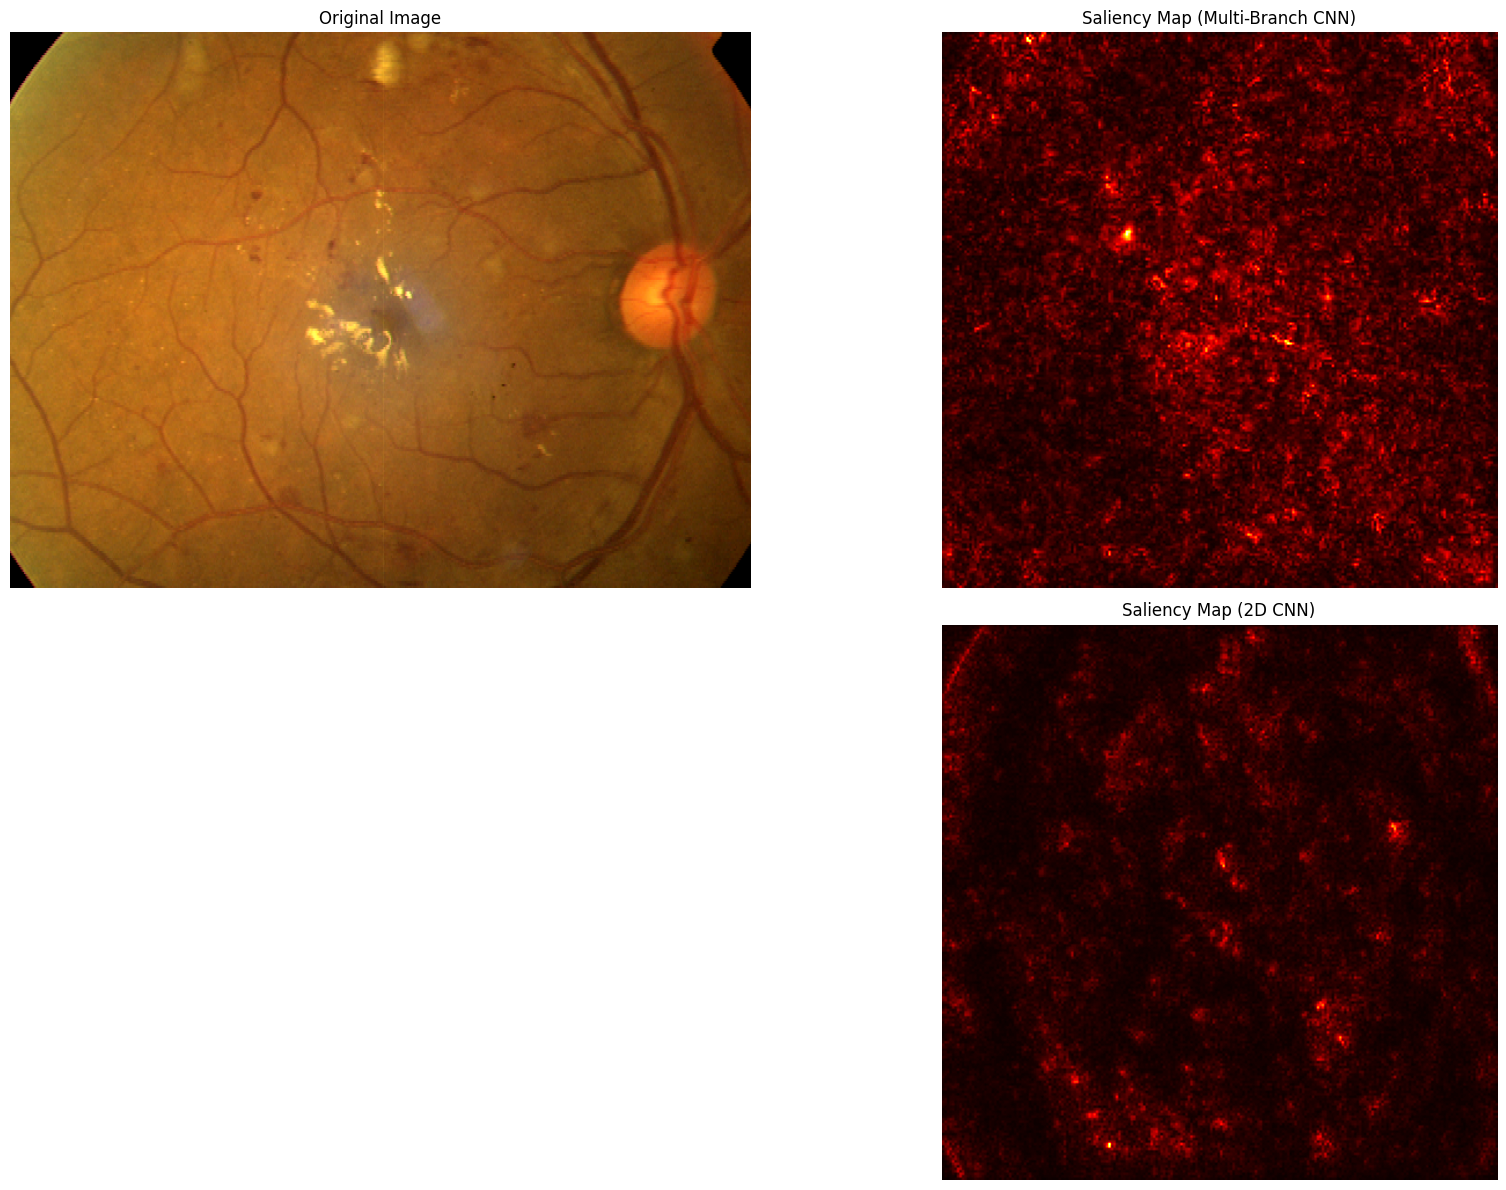

In [96]:

image_path = "/kaggle/input/aptos-2019-blindness-detection/APTOS 2019 Blindness Detection/test_images/030e06ddbb04.png"
results = predict_with_explanations(image_path, multibranch_model_1, cnn_model)


print("Multi-Branch CNN Predictions:")
print(f"Class: {results['multi_branch_cnn']['class']}")
print(f"Confidence: {results['multi_branch_cnn']['confidence'] * 100:.2f}%")
print(f"Probabilities: {results['multi_branch_cnn']['probabilities']}")

print("\n2D CNN Predictions:")
print(f"Class: {results['2d_cnn']['class']}")
print(f"Confidence: {results['2d_cnn']['confidence'] * 100:.2f}%")
print(f"Probabilities: {results['2d_cnn']['probabilities']}")

print("\nEnsemble Predictions:")
print(f"Class: {results['ensemble']['class']}")
print(f"Confidence: {results['ensemble']['confidence'] * 100:.2f}%")
print(f"Probabilities: {results['ensemble']['probabilities']}")


original_image = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
visualize_results(results, original_image)

In [97]:
from sklearn.metrics import (classification_report, cohen_kappa_score,roc_auc_score, confusion_matrix)
from sklearn.preprocessing import label_binarize
import numpy as np

y_true = true_labels
y_pred = ensemble_class_labels
y_prob = ensemble_predictions

print(classification_report(y_true, y_pred, digits=4,
      target_names=["No DR","Mild","Moderate","Severe","Prolif."]))
print("QWK:", cohen_kappa_score(y_true, y_pred, weights="quadratic"))
print("Macro AUC (OvR):", roc_auc_score(y_true, y_prob, multi_class="ovr"))

cm = confusion_matrix(y_true, y_pred)
for i in range(5):
    tn = cm.sum() - cm[i].sum() - cm[:, i].sum() + cm[i, i]
    fp = cm[:, i].sum() - cm[i, i]
    print(i, "specificity:", tn / (tn + fp))


yb_t, yb_p = (y_true > 0), (y_pred > 0)
print("Binary sens/spec:",
      (yb_t & yb_p).sum() / yb_t.sum(),
      (~yb_t & ~yb_p).sum() / (~yb_t).sum())

              precision    recall  f1-score   support

       No DR     0.9668    0.9813    0.9740       267
        Mild     0.7231    0.9216    0.8103        51
    Moderate     0.9583    0.8415    0.8961       164
      Severe     0.8438    0.9310    0.8852        29
     Prolif.     0.8913    0.8723    0.8817        47

    accuracy                         0.9229       558
   macro avg     0.8767    0.9095    0.8895       558
weighted avg     0.9293    0.9229    0.9238       558

QWK: 0.9510833601981777
Macro AUC (OvR): 0.9843408133467516
0 specificity: 0.9690721649484536
1 specificity: 0.9644970414201184
2 specificity: 0.9847715736040609
3 specificity: 0.9905482041587902
4 specificity: 0.9902152641878669
Binary sens/spec: 0.9690721649484536 0.9812734082397003
